In [1]:
# %matplotlib inline
%matplotlib widget

In [13]:
import datetime
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import pandas_ta  as ta

In [3]:
from scipy.signal import argrelextrema

In [4]:
import mplfinance as mpf

In [5]:
import MetaTrader5 as mt5

In [6]:
from matplotlib import rcParams

In [7]:
plt.style.use('bmh')
rcParams['figure.figsize'] = [12, 6]
rcParams['font.family'] = 'SimHei'

In [8]:
mt5.initialize()

True

In [9]:
# data = mt5.copy_rates_range("EURUSD", mt5.TIMEFRAME_M15, datetime.datetime(2010, 1, 1, 0), datetime.datetime(2013, 2, 18, 0)) # datetime.datetime(2010, 1, 1, 0), datetime.datetime(2024, 2, 18, 0)

In [8]:
data = mt5.copy_rates_range("EURUSD", mt5.TIMEFRAME_M1, datetime.datetime(2020, 1, 1, 0), datetime.datetime(2020, 2, 28, 0))

In [9]:
df = pd.DataFrame(data)

In [10]:
df['date'] = pd.to_datetime(df['time'], unit='s')

In [11]:
df = df.set_index('date')

In [12]:
df

,time,open,high,low,close,tick_volume,spread,real_volume
date,,,,,,,,
2019-12-31 16:00:00,1577808000,1.12381,1.12384,1.12369,1.12379,34,4,0
2019-12-31 16:01:00,1577808060,1.12379,1.12387,1.12377,1.12378,27,3,0
2019-12-31 16:02:00,1577808120,1.12382,1.12391,1.12378,1.12389,22,3,0
2019-12-31 16:03:00,1577808180,1.12389,1.12392,1.12372,1.12373,36,2,0
2019-12-31 16:04:00,1577808240,1.12373,1.12375,1.12361,1.12364,34,3,0
...,...,...,...,...,...,...,...,...
2020-02-27 15:56:00,1582818960,1.09716,1.09726,1.09713,1.09726,75,1,0
2020-02-27 15:57:00,1582819020,1.09726,1.09754,1.09720,1.09754,94,1,0
2020-02-27 15:58:00,1582819080,1.09753,1.09776,1.09749,1.09774,98,1,0


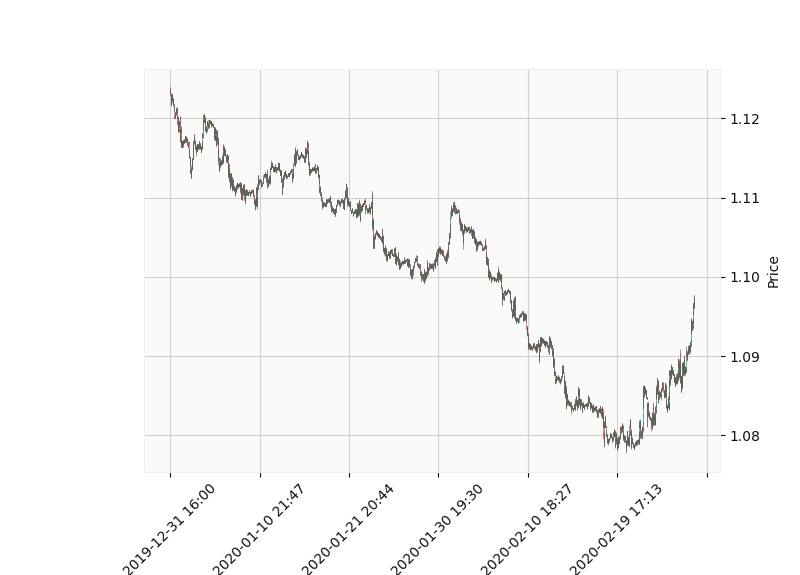

In [13]:
mpf.plot(df, type='candle', warn_too_much_data=350227, style='yahoo', datetime_format='%Y-%m-%d %H:%M')

In [9]:
data = mt5.copy_rates_range("EURUSD", mt5.TIMEFRAME_M1, datetime.datetime(2020, 1, 1, 0), datetime.datetime(2020, 4, 1, 0))

In [10]:
df = pd.DataFrame(data)
df['date'] = pd.to_datetime(df['time'], unit='s')

In [11]:
df = df.set_index('date')

In [12]:
df

,time,open,high,low,close,tick_volume,spread,real_volume
date,,,,,,,,
2019-12-31 16:00:00,1577808000,1.12381,1.12384,1.12369,1.12379,34,4,0
2019-12-31 16:01:00,1577808060,1.12379,1.12387,1.12377,1.12378,27,3,0
2019-12-31 16:02:00,1577808120,1.12382,1.12391,1.12378,1.12389,22,3,0
2019-12-31 16:03:00,1577808180,1.12389,1.12392,1.12372,1.12373,36,2,0
2019-12-31 16:04:00,1577808240,1.12373,1.12375,1.12361,1.12364,34,3,0
...,...,...,...,...,...,...,...,...
2020-03-31 15:56:00,1585670160,1.09712,1.09713,1.09682,1.09705,115,0,0
2020-03-31 15:57:00,1585670220,1.09705,1.09715,1.09692,1.09713,123,1,0
2020-03-31 15:58:00,1585670280,1.09714,1.09719,1.09692,1.09701,101,1,0


In [31]:
df['min'] = df.loc[df['low'] == df['low'].rolling(5, center=True).min()]['low'] # df.iloc[argrelextrema(df.low.values, np.less_equal, order=1)[0]]['low']
df['max'] = df.iloc[argrelextrema(df.high.values, np.greater_equal, order=1)[0]]['high']

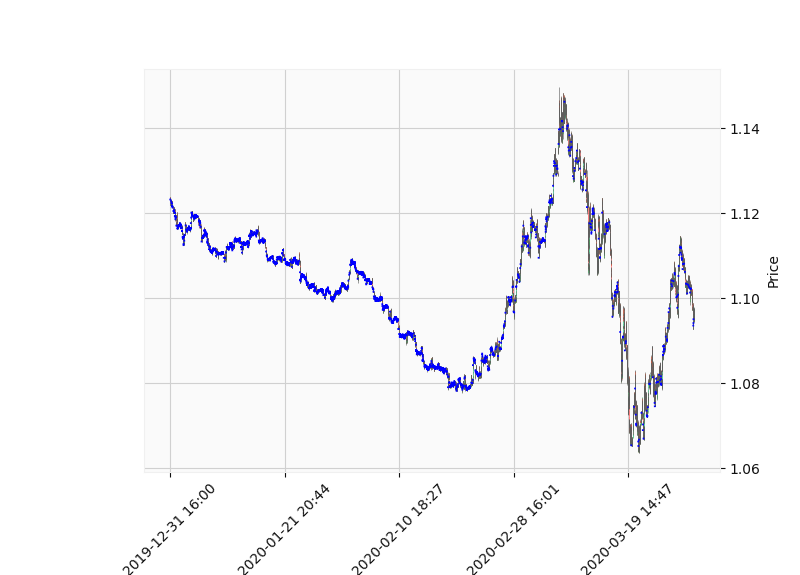

In [32]:
ap = mpf.make_addplot(df['min'], secondary_y=False, color='b')
mpf.plot(df, addplot=ap, type='candle', warn_too_much_data=373096, style='yahoo', datetime_format='%Y-%m-%d %H:%M') # returnfig=True

In [17]:
# fig = mpf.figure(style='yahoo', figsize=(12, 9))
# ax = fig.add_subplot()
# mpf.plot(df, type='candle', ax=ax, warn_too_much_data=373096, style='yahoo', datetime_format='%Y-%m-%d %H:%M', returnfig=True)
# ax.plot(df.index, df['min'])

In [23]:
df.iloc[argrelextrema(df.low.values, np.less_equal, order=1)[0]]['low']

date
2019-12-31 16:00:00    1.12369
2019-12-31 16:07:00    1.12324
2019-12-31 16:08:00    1.12324
2019-12-31 16:15:00    1.12346
2019-12-31 16:19:00    1.12362
                        ...   
2020-03-31 15:42:00    1.09632
2020-03-31 15:48:00    1.09691
2020-03-31 15:52:00    1.09641
2020-03-31 15:56:00    1.09682
2020-03-31 15:59:00    1.09680
Name: low, Length: 27681, dtype: float64

In [34]:
df.loc[df['low'] == df['low'].rolling(5, center=True).min()]

,time,open,high,low,close,tick_volume,spread,real_volume,min,max
date,,,,,,,,,,
2019-12-31 16:07:00,1577808420,1.12337,1.12337,1.12324,1.12327,24,3,0,1.12324,NaN
2019-12-31 16:08:00,1577808480,1.12325,1.12332,1.12324,1.12332,23,3,0,1.12324,NaN
2019-12-31 16:15:00,1577808900,1.12352,1.12356,1.12346,1.12352,28,3,0,1.12346,NaN
2019-12-31 16:23:00,1577809380,1.12346,1.12346,1.12331,1.12337,31,2,0,1.12331,NaN
2019-12-31 16:27:00,1577809620,1.12326,1.12338,1.12318,1.12338,42,2,0,1.12318,NaN
...,...,...,...,...,...,...,...,...,...,...
2020-03-31 15:26:00,1585668360,1.09471,1.09498,1.09467,1.09496,61,2,0,1.09467,NaN
2020-03-31 15:34:00,1585668840,1.09605,1.09619,1.09563,1.09579,213,0,0,1.09563,NaN
2020-03-31 15:48:00,1585669680,1.09732,1.09739,1.09691,1.09718,170,2,0,1.09691,NaN


In [30]:
dataM30 = mt5.copy_rates_range("EURUSD", mt5.TIMEFRAME_M30, datetime.datetime(2020, 1, 1, 0), datetime.datetime(2022, 1, 1, 0))
dataH4 = mt5.copy_rates_range("EURUSD", mt5.TIMEFRAME_H4, datetime.datetime(2020, 1, 1, 0), datetime.datetime(2022, 1, 1, 0))

In [31]:
dfM30 = pd.DataFrame(dataM30)
dfM30['date'] = pd.to_datetime(dfM30['time'], unit='s')

dfH4 = pd.DataFrame(dataH4)
dfH4['date'] = pd.to_datetime(dfH4['time'], unit='s')

In [32]:
dfM30['ma60'] = dfM30.ta.sma(60)
dfH4['ma60'] = dfH4.ta.sma(60)

In [33]:
dfM30 = dfM30.set_index('date')
dfH4 = dfH4.set_index('date')

In [29]:
# dfH4_m60 = dfH4['ma60']
# dfH4_m60 = dfH4_m60.to_frame()
# dfH4_m60 = dfH4_m60.set_index(dfM30.index)

In [44]:
# pd.merge?
dfM30.ma60.to_frame().rename(columns={'ma60': 'ma60M30'})

,ma60M30
date,
2019-12-31 16:00:00,NaN
2019-12-31 16:30:00,NaN
2019-12-31 17:00:00,NaN
2019-12-31 17:30:00,NaN
2019-12-31 18:00:00,NaN
...,...
2021-12-31 14:00:00,1.131963
2021-12-31 14:30:00,1.131976
2021-12-31 15:00:00,1.131998


In [45]:
df_ma = dfM30.ma60.to_frame().rename(columns={'ma60': 'ma60M30'}).merge(dfH4.ma60.to_frame().rename(columns={'ma60': 'ma60H4'}), left_index=True, right_index=True, how='left')

In [46]:
df_ma

,ma60M30,ma60H4
date,,
2019-12-31 16:00:00,NaN,NaN
2019-12-31 16:30:00,NaN,NaN
2019-12-31 17:00:00,NaN,NaN
2019-12-31 17:30:00,NaN,NaN
2019-12-31 18:00:00,NaN,NaN
...,...,...
2021-12-31 14:00:00,1.131963,NaN
2021-12-31 14:30:00,1.131976,NaN
2021-12-31 15:00:00,1.131998,NaN


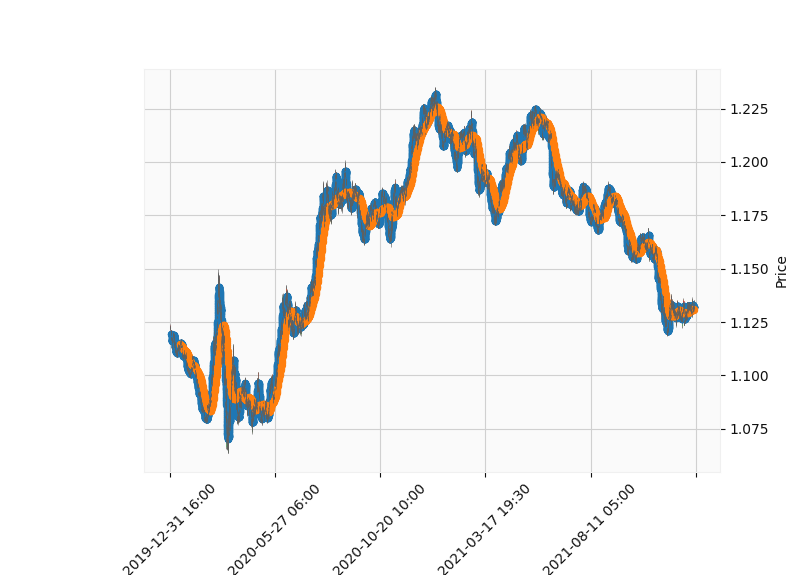

In [53]:
# plt.plot(dfM30.ma60, label='M30')
# plt.plot(dfH4.ma60, label='H4')
# plt.legend()
# plt.show()

apds = [
    # mpf.make_addplot(data=df['maxmin'], secondary_y=False, type='scatter'),
    # mpf.make_addplot(data=dfM30['ma60'], secondary_y=False, type='line', color='r'),
    # mpf.make_addplot(data=dfH4['ma60'], secondary_y=False, type='line', color='b'),
    mpf.make_addplot(data=df_ma, secondary_y=False, type='scatter'),
       ]
mpf.plot(dfM30, addplot=apds, type='candle', warn_too_much_data=dfM30.shape[0], style='yahoo', datetime_format='%Y-%m-%d %H:%M') # returnfig=True

In [21]:
plt.close()